# Exploration des consommations et choix des features

Ordre de travail : **période train → qualité et exploration → analyse météo → choix des colonnes**. Un site, une heure ; cible : **consumption_kwh**. Aucun entraînement dans ce notebook.

### Lancer le notebook

Depuis la racine du projet, avec Python 3.12 ou supérieur, le CSV dans **.data/ml/raw/all_sites_combined.csv** et les sept fichiers **SITE00X_metadata.json** dans **.data/ml/raw/metadata/** :

~~~bash
python3 -m venv services/ml-service/notebook/.venv
source services/ml-service/notebook/.venv/bin/activate
python -m pip install -r services/ml-service/requirements-notebooks.txt
python -m jupyterlab services/ml-service/notebook/01_exploration_consommation.ipynb
~~~

Pour les lancements suivants, réactiver l’environnement puis lancer JupyterLab. Pour un autre CSV, définir **ML_EXPLORATION_CSV** ; pour un autre dossier de métadonnées, définir **ML_EXPLORATION_METADATA**. Les chemins relatifs partent de la racine du projet. **.data/** est ignoré par Git : CSV et métadonnées sont à récupérer séparément.

**Restart Kernel and Run All Cells** recalcule les analyses sur la période **train : janvier 2023 à juin 2024**. Le CSV est lu sans être modifié ; validation et test ne servent pas à choisir les features. Les lignes à cible manquante sont comptées dans le contrôle qualité et écartées des analyses de consommation. Les zéros sont conservés. **is_working_hours** est recalculé en mémoire avec les horaires et jours des métadonnées ; le flag original reste dans **raw** pour comparaison.

**La génération des Parquet se fait dans le module Python training.prepare_data**, avec la commande Docker de la section 10. Le notebook ne lit aucun Parquet et ne génère aucun fichier de données. Les fonctions de lecture des plannings et de recalcul du flag sont partagées avec ce module.

Les tableaux et graphiques enregistrés concernent train. Relancer le notebook recalcule les analyses depuis le CSV original sans le modifier. La liste finale décrit le schéma partagé avec les scripts Python.


In [ ]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
pd.options.display.float_format = "{:.2f}".format
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "services/ml-service/requirements-notebooks.txt").is_file())
SOURCE = Path(os.environ.get("ML_EXPLORATION_CSV", ".data/ml/raw/all_sites_combined.csv")).expanduser()
SOURCE = SOURCE if SOURCE.is_absolute() else ROOT / SOURCE
METADATA = Path(os.environ.get("ML_EXPLORATION_METADATA", ".data/ml/raw/metadata")).expanduser()
METADATA = METADATA if METADATA.is_absolute() else ROOT / METADATA
ML_SERVICE = ROOT / "services/ml-service"
if str(ML_SERVICE) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE))
from training.data import COLUMNS as PARQUET_COLUMNS, FEATURES, TARGET
from training.prepare_data import load_site_schedules, recalculate_working_hours
TRAIN_START, TRAIN_END = pd.Timestamp("2023-01-01"), pd.Timestamp("2024-07-01")

def read_training_csv(source):
    parts = []
    for chunk in pd.read_csv(source, chunksize=20000):
        timestamps = pd.to_datetime(chunk["timestamp"], errors="raise")
        selected = timestamps.ge(TRAIN_START) & timestamps.lt(TRAIN_END)
        part = chunk.loc[selected].copy()
        part["timestamp"] = timestamps.loc[selected]
        if not part.empty:
            parts.append(part)
    if not parts:
        raise ValueError("Aucune ligne dans la période train.")
    return pd.concat(parts, ignore_index=True)

# L'analyse reçoit seulement train ; l'export est une commande Python séparée.
raw = read_training_csv(SOURCE)
assert not raw.duplicated(["site_id", "timestamp"]).any(), "Résoudre les doublons avant de continuer."
SITE_SCHEDULES = load_site_schedules(METADATA, raw.site_id.unique())
df = recalculate_working_hours(raw.dropna(subset=[TARGET]), SITE_SCHEDULES)
assert np.isfinite(df[TARGET]).all() and df[TARGET].ge(0).all()
SITES = sorted(df.site_id.unique())
display(Markdown(
    f"**Train uniquement : {len(raw):,} lignes source ; {len(df):,} cibles connues ; {len(SITES)} sites.** "
    f"Période : {TRAIN_START:%d/%m/%Y} au {(TRAIN_END - pd.Timedelta(days=1)):%d/%m/%Y}. "
    "Les statistiques de consommation utilisent les cibles connues, zéros inclus."
))
display(Markdown("**Colonnes disponibles avant sélection :** " + ", ".join(raw.columns) + "."))


## 1. Qualité des données

Repérer les manquants, doublons, heures absentes et valeurs à examiner. Les champs vides restent distincts des zéros ; aucune valeur n'est corrigée.

In [ ]:
missing = raw.isna().sum()
display(pd.DataFrame({
    "valeurs_manquantes": missing[missing.gt(0)],
    "pourcentage": missing[missing.gt(0)] / len(raw) * 100,
}))
duplicates = raw.duplicated(["site_id", "timestamp"]).sum()
missing_hours = sum(
    len(pd.date_range(group.timestamp.min(), group.timestamp.max(), freq="h")) - group.timestamp.nunique()
    for _, group in raw.groupby("site_id")
)
daily_hours = raw.groupby(["site_id", raw.timestamp.dt.date]).timestamp.nunique()
partial_days = daily_hours.lt(24).sum()
calendar_errors = (
    raw.hour.ne(raw.timestamp.dt.hour) | raw.day_of_week.ne(raw.timestamp.dt.dayofweek)
    | raw.month.ne(raw.timestamp.dt.month) | raw.is_weekend.ne(raw.timestamp.dt.dayofweek.ge(5).astype(int))
    | raw.day_name.ne(raw.timestamp.dt.day_name())
).sum()
display(Markdown(
    f"**Contrôles :** {duplicates} doublons site/heure ; {missing_hours} heures absentes entre les bornes de chaque site ; "
    f"{calendar_errors} lignes au calendrier incohérent ; {raw[TARGET].lt(0).sum()} consommations négatives.\n\n"
    f"**À retenir :** {missing[TARGET]:,} consommations manquantes ({missing[TARGET] / len(raw):.2%}), "
    f"{raw[TARGET].eq(0).sum():,} zéros et {partial_days} journées partiellement présentes. "
    "Ces contrôles concernent uniquement la période train. "
    "Les moyennes suivantes utilisent uniquement les valeurs disponibles, zéros inclus."
))

## 2. Différences entre sites

Comparer niveaux, dispersion, zéros et pics. Les points au-delà des moustaches servent au repérage ; ils ne prouvent pas une erreur de mesure.

,type,n_valides,moyenne,mediane,ecart_type,maximum,zeros
site_id,,,,,,,
SITE001,office,12827,110.58,84.65,61.02,1006.26,201
SITE002,factory,12822,605.89,466.02,341.90,3225.29,211
SITE003,datacenter,12813,845.61,808.40,207.89,2623.62,152
SITE004,retail,12837,261.77,207.90,146.85,1304.70,177
SITE005,hospital,12830,539.42,516.45,145.50,2115.03,209
SITE006,office,12844,109.24,84.34,57.37,595.84,185
SITE007,factory,12807,613.29,461.09,350.51,4599.76,208


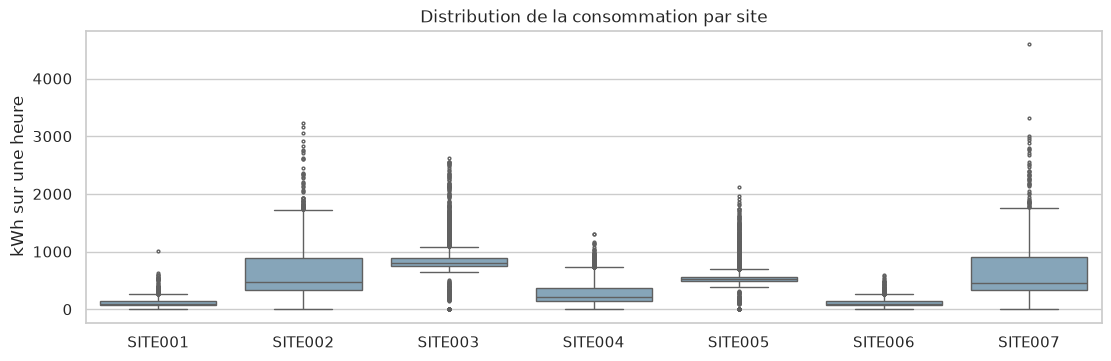

**Constat :** les moyennes vont de 109.24 à 845.61 kWh par heure observée. Le maximum atteint 4599.76 kWh.

**Conséquence :** évaluer les futurs résultats par site. Les zéros et pics nécessitent une vérification métier avant toute exclusion.

In [2]:
stats = df.groupby("site_id").agg(
    type=("site_type", "first"), n_valides=(TARGET, "count"), moyenne=(TARGET, "mean"),
    mediane=(TARGET, "median"), ecart_type=(TARGET, "std"), maximum=(TARGET, "max"),
    zeros=(TARGET, lambda values: values.eq(0).sum()),
)
# Le taux de cible manquante se calcule sur les lignes source, dans la section qualité.
display(stats)
fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
sns.boxplot(data=df, x="site_id", y=TARGET, order=SITES, color="#7da7c2", fliersize=2, ax=ax)
ax.set(xlabel="", ylabel="kWh sur une heure", title="Distribution de la consommation par site")
plt.show()
plt.close(fig)
display(Markdown(
    f"**Constat :** les moyennes vont de {stats.moyenne.min():.2f} à {stats.moyenne.max():.2f} kWh par heure observée. "
    f"Le maximum atteint {df[TARGET].max():.2f} kWh.\n\n"
    "**Conséquence :** évaluer les futurs résultats par site. Les zéros et pics nécessitent une vérification métier avant toute exclusion."
))

## 3. Profils temporels

L'heure, le jour et le mois peuvent-ils expliquer les variations ? Comparer les profils séparément par site. Les courbes sont descriptives ; elles ne mesurent pas encore l'apport prédictif d'une variable.

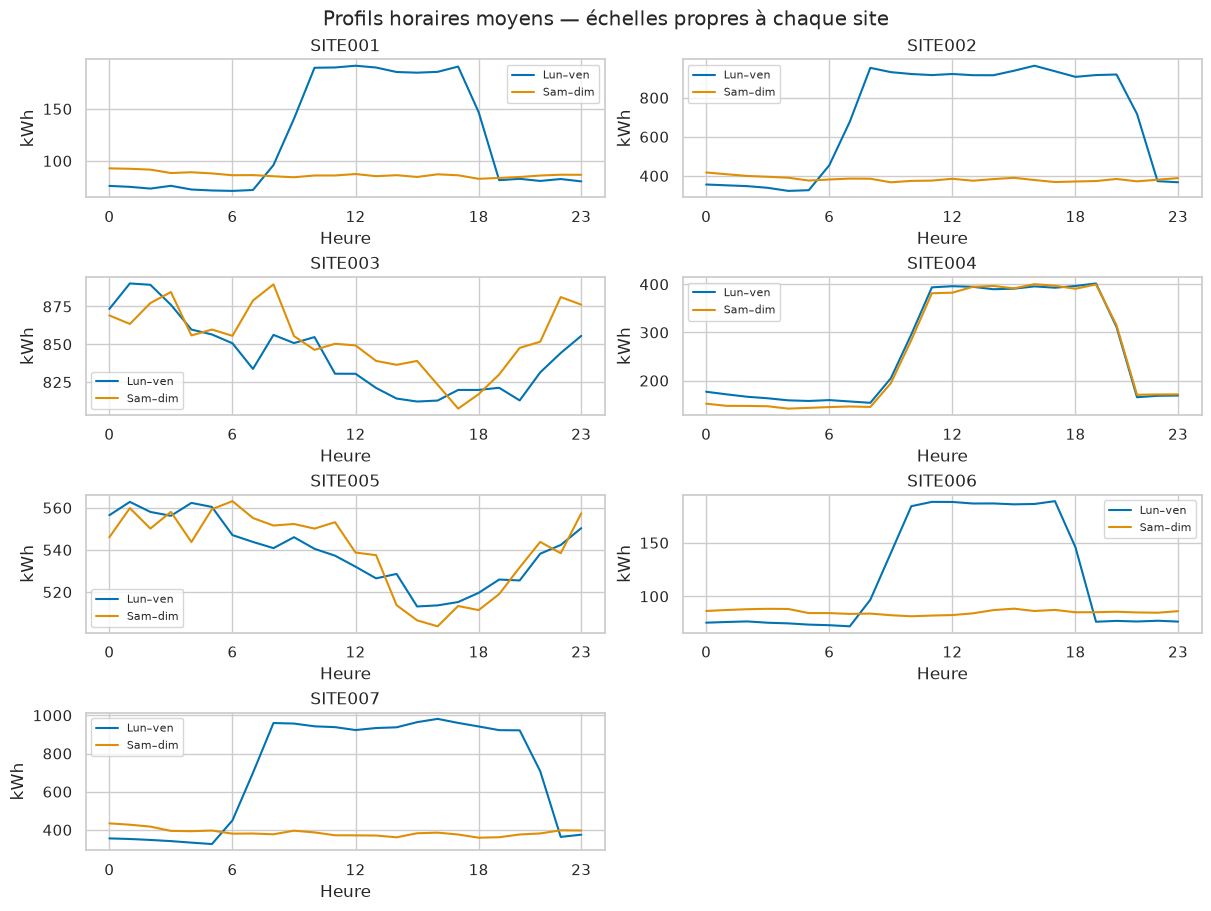

**Écart de moyenne week-end / semaine :** SITE001 : -27.7 % ; SITE002 : -44.8 % ; SITE003 : +1.3 % ; SITE004 : -2.8 % ; SITE005 : +0.1 % ; SITE006 : -28.2 % ; SITE007 : -45.2 %.

**À retenir :** les effets du calendrier diffèrent selon les sites.

In [3]:
hourly = df.groupby([
    "site_id", df.timestamp.dt.dayofweek.ge(5).rename("weekend"),
    df.timestamp.dt.hour.rename("heure"),
])[TARGET].agg(n="count", moyenne="mean").reset_index()
fig, axes = plt.subplots((len(SITES) + 1) // 2, 2, figsize=(12, 9), layout="constrained")
for site, ax in zip(SITES, np.asarray(axes).ravel()):
    for weekend, label in [(False, "Lun–ven"), (True, "Sam–dim")]:
        profile = hourly.loc[hourly.site_id.eq(site) & hourly.weekend.eq(weekend)]
        ax.plot(profile.heure, profile.moyenne, label=label)
    ax.set(title=site, xlabel="Heure", ylabel="kWh", xticks=[0, 6, 12, 18, 23])
    ax.legend(fontsize=8)
for ax in np.asarray(axes).ravel()[len(SITES):]:
    ax.remove()
fig.suptitle("Profils horaires moyens — échelles propres à chaque site")
plt.show()
plt.close(fig)

weekend_means = df.groupby(["site_id", df.timestamp.dt.dayofweek.ge(5)])[TARGET].mean().unstack()
weekend_change = (weekend_means[True] / weekend_means[False] - 1) * 100
display(Markdown(
    "**Écart de moyenne week-end / semaine :** "
    + " ; ".join(f"{site} : {value:+.1f} %" for site, value in weekend_change.items())
    + ".\n\n**À retenir :** les effets du calendrier diffèrent selon les sites."
))

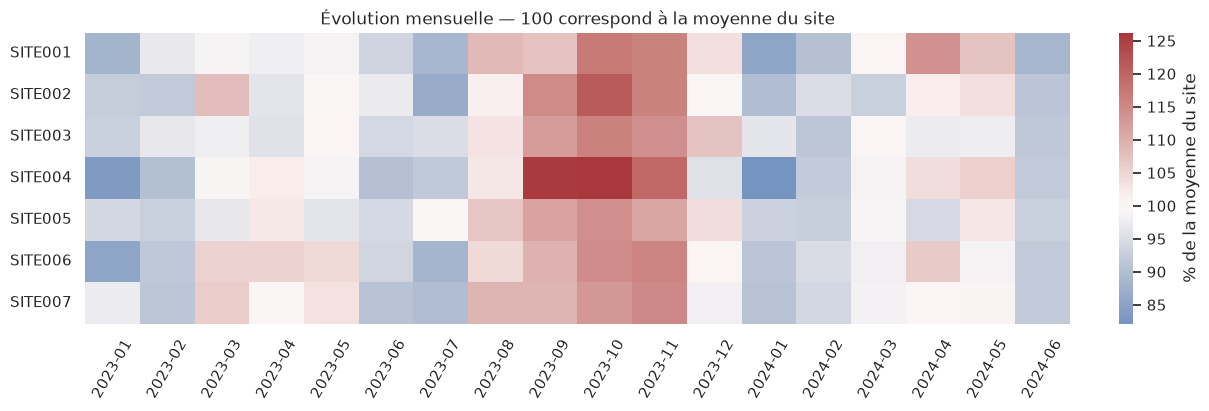

**Interprétation :** comparer les mêmes mois entre 2023 et 2024 pour examiner la répétition des variations. Le mois et l'heure restent des candidats à évaluer. Les moyennes n'inventent aucune valeur manquante ; elles ne représentent pas un total mensuel.

In [4]:
monthly = df.groupby(["site_id", df.timestamp.dt.strftime("%Y-%m").rename("mois")])[TARGET].agg(
    n="count", moyenne="mean",
).reset_index()
monthly["moyenne_relative_pct"] = monthly.moyenne / monthly.site_id.map(stats.moyenne) * 100
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
sns.heatmap(monthly.pivot(index="site_id", columns="mois", values="moyenne_relative_pct"),
            cmap="vlag", center=100, cbar_kws={"label": "% de la moyenne du site"}, ax=ax)
ax.set(title="Évolution mensuelle — 100 correspond à la moyenne du site", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=60)
plt.show()
plt.close(fig)
display(Markdown(
    "**Interprétation :** comparer les mêmes mois entre 2023 et 2024 pour examiner la répétition des variations. "
    "Le mois et l'heure restent des candidats à évaluer. Les moyennes n'inventent aucune valeur manquante ; "
    "elles ne représentent pas un total mensuel."
))

## 4. Relations entre variables

Comparer les corrélations de Pearson par site et sur l'ensemble des sites. Chaque case indique la corrélation puis le nombre de paires disponibles. Une faible corrélation n'exclut pas une relation non linéaire ; une forte corrélation ne prouve ni causalité ni utilité pour la prévision.

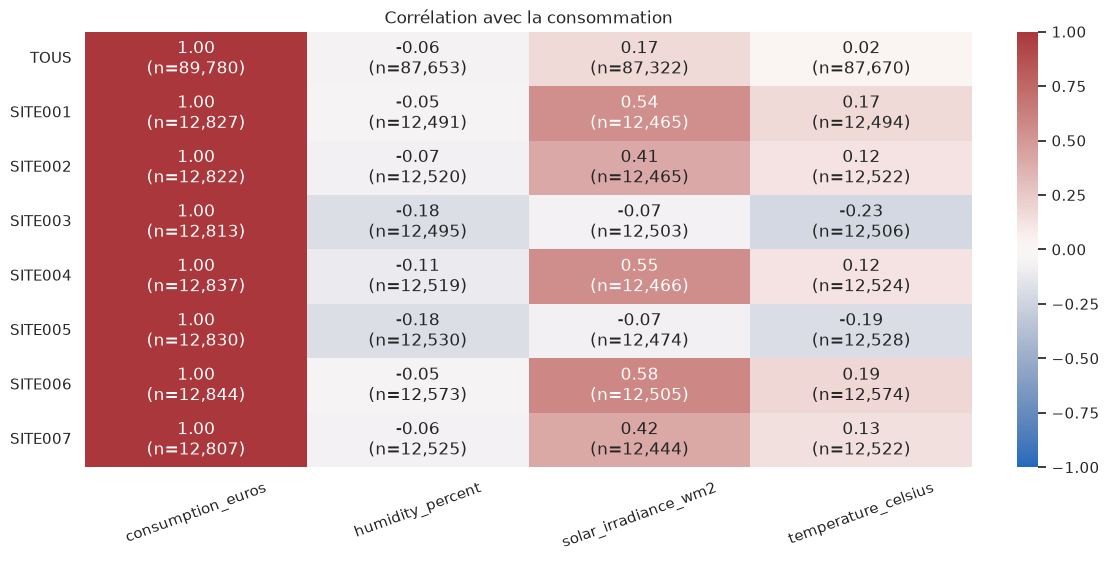

**Coût :** l'écart maximal avec 0,15 × kWh vaut 0.005500 €. Le coût observé est très proche de la cible et ne sera pas connu pour l'heure future : il faut l'écarter des entrées de cette prévision.

**Météo :** les relations varient selon les sites. La météo réellement observée pendant l'heure future n'est pas disponible au lancement ; son éventuel usage nécessiterait des prévisions météo.

In [5]:
variables = ["temperature_celsius", "humidity_percent", "solar_irradiance_wm2", "consumption_euros"]
records = []
for scope, group in [("TOUS", df), *list(df.groupby("site_id"))]:
    for variable in variables:
        pairs = group[[TARGET, variable]].dropna()
        records.append({"site": scope, "variable": variable, "n": len(pairs),
                        "correlation": pairs.corr().iloc[0, 1]})
relations = pd.DataFrame(records)
correlations = relations.pivot(index="site", columns="variable", values="correlation").reindex(["TOUS", *SITES])
counts = relations.pivot(index="site", columns="variable", values="n").reindex_like(correlations)
annotations = correlations.map(lambda value: f"{value:.2f}") + "\n(n=" + counts.map(lambda value: f"{value:,}") + ")"
fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
sns.heatmap(correlations, annot=annotations, fmt="", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Corrélation avec la consommation", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.show()
plt.close(fig)

cost_pairs = df[[TARGET, "consumption_euros"]].dropna()
cost_error = (cost_pairs.consumption_euros - .15 * cost_pairs[TARGET]).abs().max()
display(Markdown(
    f"**Coût :** l'écart maximal avec 0,15 × kWh vaut {cost_error:.6f} €. "
    "Le coût observé est très proche de la cible et ne sera pas connu pour l'heure future : "
    "il faut l'écarter des entrées de cette prévision.\n\n"
    "**Météo :** les relations varient selon les sites. La météo réellement observée pendant l'heure future "
    "n'est pas disponible au lancement ; son éventuel usage nécessiterait des prévisions météo."
))

## 5. Autocorrélation : 24 h, 7 jours et 30 jours

Comparer la consommation à celle du **même site**, à **t − 24 h**, **t − 168 h** et **t − 720 h**. Chaque valeur est une corrélation de Pearson entre ces deux consommations ; **n** indique le nombre de paires disponibles.

Les dates sont décalées exactement : aucune compression des heures ni imputation. Les paires contenant une valeur manquante sont écartées seulement après l'alignement ; les zéros restent présents. Trente jours ne représentent pas forcément le même jour de semaine.

/tmp/ipykernel_10/1324682190.py:8: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pairs = pd.concat({"actuelle": series, "passee": delayed}, axis=1).dropna()
/tmp/ipykernel_10/1324682190.py:8: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pairs = pd.concat({"actuelle": series, "passee": delayed}, axis=1).dropna()
/tmp/ipykernel_10/1324682190.py:8: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=Fal

lag,24 h,7 j,30 j
site,,,
SITE001,"0.465 (n=12,506)","0.592 (n=12,381)","0.300 (n=11,840)"
SITE002,"0.424 (n=12,495)","0.635 (n=12,360)","0.217 (n=11,827)"
SITE003,"0.126 (n=12,486)","0.180 (n=12,358)","0.097 (n=11,820)"
SITE004,"0.623 (n=12,528)","0.597 (n=12,396)","0.593 (n=11,879)"
SITE005,"0.104 (n=12,510)","0.076 (n=12,372)","0.059 (n=11,853)"
SITE006,"0.518 (n=12,552)","0.682 (n=12,398)","0.347 (n=11,873)"
SITE007,"0.431 (n=12,470)","0.631 (n=12,336)","0.200 (n=11,817)"


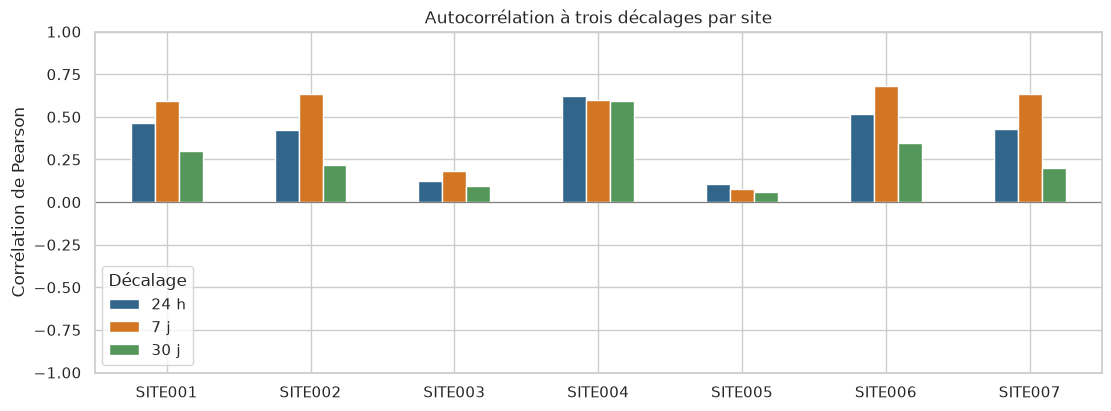

**Constats :** 7 jours présente la corrélation la plus élevée sur 5 sites sur 7, contre 2 pour 24 h et 0 pour 30 jours. Le décalage de 30 jours est le moins corrélé sur 7 sites. À 7 jours, les coefficients varient de 0.076 à 0.682.

**Proposition :** étudier en priorité 7 jours et 24 h comme entrées candidates, puis comparer leur apport réel au-delà du calendrier. Ces corrélations brutes, calculées avec des effectifs différents, peuvent refléter les cycles habituels ou une tendance ; elles ne démontrent pas encore un gain de prévision.

**Disponibilité :** ces trois lags peuvent être connus à 00 h 05 pour toutes les heures de la journée à prévoir, si l'historique correspondant est collecté. La future évaluation devra respecter cette heure de lancement.

In [6]:
LAGS = {"24 h": 24, "7 j": 168, "30 j": 720}
assert not df.duplicated(["site_id", "timestamp"]).any(), "Résoudre les doublons avant l'autocorrélation."
lag_records = []
for site, group in df.groupby("site_id"):
    series = group.set_index("timestamp")[TARGET].sort_index()
    for label, hours in LAGS.items():
        delayed = series.shift(freq=pd.Timedelta(hours=hours))
        pairs = pd.concat({"actuelle": series, "passee": delayed}, axis=1).dropna()
        lag_records.append({
            "site": site, "lag": label, "n_paires": len(pairs),
            "correlation": pairs.corr().loc["actuelle", "passee"],
        })
autocorrelations = pd.DataFrame(lag_records)
lag_correlations = autocorrelations.pivot(index="site", columns="lag", values="correlation").reindex(index=SITES, columns=LAGS)
lag_counts = autocorrelations.pivot(index="site", columns="lag", values="n_paires").reindex_like(lag_correlations)
lag_table = lag_correlations.map(lambda value: f"{value:.3f}") + " (n=" + lag_counts.map(lambda n: f"{n:,}") + ")"
display(lag_table)

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
lag_correlations.plot.bar(ax=ax, rot=0, color=["#32658a", "#d27624", "#55965b"])
ax.axhline(0, color="grey", linewidth=.8)
ax.set(title="Autocorrélation à trois décalages par site", xlabel="", ylabel="Corrélation de Pearson", ylim=(-1, 1))
ax.legend(title="Décalage")
plt.show()
plt.close(fig)

lag_winners = lag_correlations.idxmax(axis=1).value_counts()
lag_30_lowest = lag_correlations["30 j"].eq(lag_correlations.min(axis=1)).sum()
display(Markdown(
    f"**Constats :** 7 jours présente la corrélation la plus élevée sur {lag_winners.get('7 j', 0)} sites sur {len(SITES)}, "
    f"contre {lag_winners.get('24 h', 0)} pour 24 h et {lag_winners.get('30 j', 0)} pour 30 jours. "
    f"Le décalage de 30 jours est le moins corrélé sur {lag_30_lowest} sites. "
    f"À 7 jours, les coefficients varient de {lag_correlations['7 j'].min():.3f} à {lag_correlations['7 j'].max():.3f}.\n\n"
    "**Proposition :** étudier en priorité 7 jours et 24 h comme entrées candidates, puis comparer leur apport réel "
    "au-delà du calendrier. Ces corrélations brutes, calculées avec des effectifs différents, peuvent refléter "
    "les cycles habituels ou une tendance ; elles ne démontrent pas encore un gain de prévision.\n\n"
    "**Disponibilité :** ces trois lags peuvent être connus à 00 h 05 pour toutes les heures de la journée à prévoir, "
    "si l'historique correspondant est collecté. La future évaluation devra respecter cette heure de lancement."
))

## 6. Température : pertinence exploratoire sur train

Cette analyse utilise **df**, la période train déjà chargée, avant l’export. Elle ne consulte aucun résultat de modèle.

On examine la consommation moyenne par tranche de **5 °C**, avec les effectifs. La couleur exprime le niveau relatif à la moyenne du site ; les annotations donnent les kWh et **n**. Les tranches rares restent visibles.

On examine ensuite les écarts à la consommation moyenne du **même site, à la même heure, le même jour de semaine et le même mois**. C’est un contrôle descriptif du calendrier, qui aide à examiner une association résiduelle sans démontrer une causalité. La courbe affiche seulement les tranches avec **n ≥ 30** ; ce seuil concerne l’affichage, pas le nettoyage des données.

Enfin, une comparaison de **janvier à juin 2023** avec **janvier à juin 2024**, deux sous-périodes de train couvrant les mêmes mois, examine la répétition du contraste entre températures douces (**15–25 °C**) et chaudes (**25–35 °C**). Chaque sous-période utilise son propre contrôle du calendrier. Les effectifs et les écarts sont présentés même quand la relation varie selon les sites.

Une association cohérente peut justifier une **feature candidate**. Elle ne garantit pas un gain de prévision. La nature intérieure ou extérieure de la température et sa disponibilité au lancement de la prévision restent à confirmer.


**Train uniquement : 89,780 lignes, 7 sites**, du 01/01/2023 au 30/06/2024. **1,343 consommations à zéro conservées.**

,paires_disponibles,NULL,NULL_pct,minimum,maximum
temperature_celsius,87670,2110,2.35,-5.10,36.30
humidity_percent,87653,2127,2.37,30.00,95.00
solar_irradiance_wm2,87322,2458,2.74,0.00,1178.40


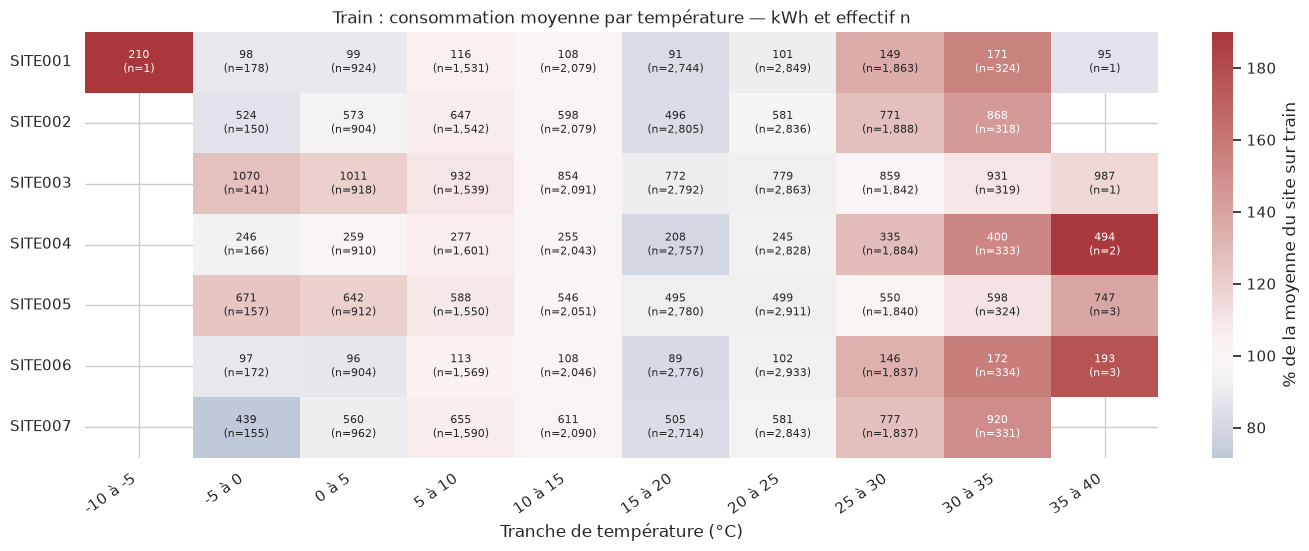

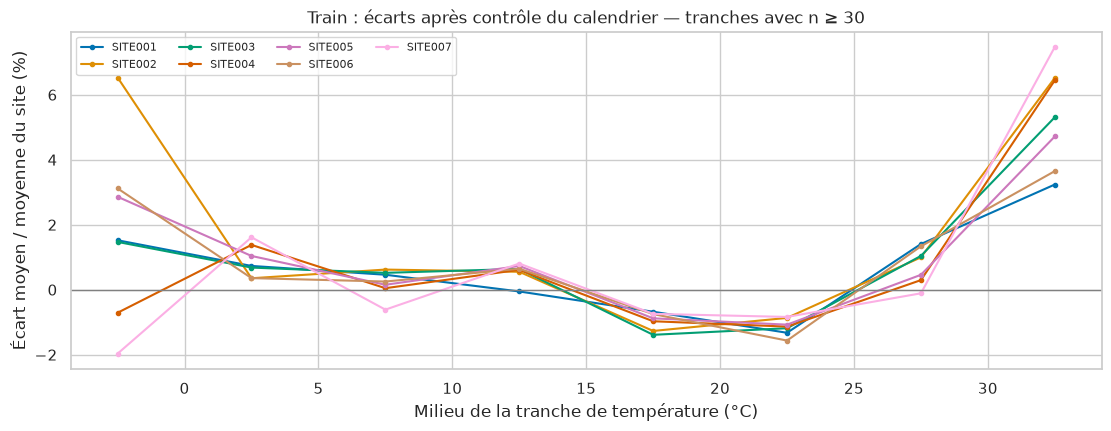

**Stabilité sur train : chaud (25–35 °C) moins doux (15–25 °C), après contrôle du calendrier.** Écart rapporté à la moyenne du site sur chaque période ; n = observations douces/chaudes. Le seuil de 30 indique seulement quand le contraste est affichable.

periode,Jan–juin 2023,Jan–juin 2024
site,,
SITE001,"+2.48% (n=2,507/1,091)","+2.43% (n=2,543/1,096)"
SITE002,"+2.18% (n=2,575/1,094)","+3.11% (n=2,507/1,112)"
SITE003,"+2.25% (n=2,541/1,098)","+3.01% (n=2,576/1,063)"
SITE004,"+2.53% (n=2,485/1,113)","+1.67% (n=2,563/1,104)"
SITE005,"+2.10% (n=2,588/1,069)","+1.19% (n=2,554/1,095)"
SITE006,"+0.96% (n=2,566/1,095)","+4.09% (n=2,588/1,076)"
SITE007,"+1.79% (n=2,513/1,056)","+1.56% (n=2,509/1,110)"


**Constat descriptif :** sur **7 sites comparables**, le contraste chaud–doux est positif dans les deux sous-périodes pour **7 sites**. Les amplitudes et les autres cas restent visibles dans le tableau ; ils ne doivent pas être masqués.

**Choix exploratoire :** retenir la température comme candidate supplémentaire aux variables de calendrier et aux lags. La relation doit être examinée par site, avec les effectifs et les résultats après contrôle du calendrier. **Aucun gain de prévision ni lien causal n’est déduit de ces graphiques.**

In [7]:
# Données train déjà disponibles : aucun fichier préparé n'est nécessaire pour l'analyse.
WX_TARGET = TARGET
WX_COLUMNS = ["temperature_celsius", "humidity_percent", "solar_irradiance_wm2"]
wx_train = df.copy()
assert wx_train.timestamp.ge(TRAIN_START).all() and wx_train.timestamp.lt(TRAIN_END).all()
assert wx_train[WX_TARGET].notna().all()
wx_sites = sorted(wx_train.site_id.unique())
wx_means = wx_train.groupby("site_id", observed=True)[WX_TARGET].mean()
wx_quality = pd.DataFrame({
    "paires_disponibles": wx_train[WX_COLUMNS].count(),
    "NULL": wx_train[WX_COLUMNS].isna().sum(),
    "NULL_pct": 100 * wx_train[WX_COLUMNS].isna().mean(),
    "minimum": wx_train[WX_COLUMNS].min(), "maximum": wx_train[WX_COLUMNS].max(),
})
display(Markdown(
    f"**Train uniquement : {len(wx_train):,} lignes, {len(wx_sites)} sites**, "
    f"du {wx_train.timestamp.min():%d/%m/%Y} au {wx_train.timestamp.max():%d/%m/%Y}. "
    f"**{wx_train[WX_TARGET].eq(0).sum():,} consommations à zéro conservées.**"
))
display(wx_quality)

# Moyenne descriptive du calendrier sur train ; aucun modèle n’est ajusté.
wx_calendar = wx_train.groupby(["site_id", "hour", "day_of_week", "month"], observed=True)[WX_TARGET].transform("mean")
wx_work = wx_train.assign(ecart_calendrier=wx_train[WX_TARGET] - wx_calendar).dropna(subset=["temperature_celsius"]).copy()
wx_edges = np.arange(np.floor(wx_work.temperature_celsius.min() / 5) * 5,
                     (np.floor(wx_work.temperature_celsius.max() / 5) + 2) * 5, 5)
wx_work["tranche"] = pd.cut(wx_work.temperature_celsius, wx_edges, right=False)
wx_bins = wx_work.groupby(["site_id", "tranche"], observed=False).agg(
    moyenne_kwh=(WX_TARGET, "mean"), n=(WX_TARGET, "count"), ecart=("ecart_calendrier", "mean"),
)
wx_values = wx_bins.moyenne_kwh.unstack().reindex(wx_sites)
wx_counts = wx_bins.n.unstack().reindex_like(wx_values)
wx_relative = wx_values.div(wx_means, axis=0) * 100
wx_annotations = pd.DataFrame("", index=wx_values.index, columns=wx_values.columns)
for site in wx_sites:
    for interval in wx_values.columns:
        if pd.notna(wx_values.loc[site, interval]):
            wx_annotations.loc[site, interval] = f"{wx_values.loc[site, interval]:.0f}\n(n={wx_counts.loc[site, interval]:,})"
wx_fig_bins, ax = plt.subplots(figsize=(13, 5.4), layout="constrained")
sns.heatmap(wx_relative, annot=wx_annotations, fmt="", cmap="vlag", center=100,
            annot_kws={"fontsize": 8}, cbar_kws={"label": "% de la moyenne du site sur train"}, ax=ax)
ax.set(title="Train : consommation moyenne par température — kWh et effectif n",
       xlabel="Tranche de température (°C)", ylabel="")
ax.set_xticklabels([f"{v.left:g} à {v.right:g}" for v in wx_values.columns], rotation=35, ha="right")
ax.tick_params(axis="y", rotation=0)
plt.show()
plt.close(wx_fig_bins)

wx_adjusted = wx_bins.ecart.unstack().reindex(wx_sites).div(wx_means, axis=0) * 100
# Seuil d’affichage seulement : toutes les données restent dans wx_train et wx_bins.
wx_adjusted = wx_adjusted.where(wx_counts.ge(30))
wx_fig_calendar, ax = plt.subplots(figsize=(11, 4.2), layout="constrained")
for site in wx_sites:
    ax.plot([v.mid for v in wx_adjusted.columns], wx_adjusted.loc[site], marker="o", markersize=3, label=site)
ax.axhline(0, color="grey", linewidth=1)
ax.set(title="Train : écarts après contrôle du calendrier — tranches avec n ≥ 30",
       xlabel="Milieu de la tranche de température (°C)", ylabel="Écart moyen / moyenne du site (%)")
ax.legend(ncol=4, fontsize=8)
plt.show()
plt.close(wx_fig_calendar)
# Répétition du contraste sur les mêmes mois de deux années, au sein de train.
wx_half = wx_train.loc[wx_train.timestamp.dt.month.le(6)].copy()
wx_half["periode"] = wx_half.timestamp.dt.year
wx_half["ajustee"] = wx_half[WX_TARGET] - wx_half.groupby(
    ["periode", "site_id", "hour", "day_of_week", "month"], observed=True
)[WX_TARGET].transform("mean")
wx_period_means = wx_half.groupby(["periode", "site_id"], observed=True)[WX_TARGET].mean()
wx_stability_records = []
for (period, site), group in wx_half.groupby(["periode", "site_id"], observed=True):
    mild = group.loc[group.temperature_celsius.ge(15) & group.temperature_celsius.lt(25), "ajustee"]
    warm = group.loc[group.temperature_celsius.ge(25) & group.temperature_celsius.lt(35), "ajustee"]
    enough = len(mild) >= 30 and len(warm) >= 30
    contrast = 100 * (warm.mean() - mild.mean()) / wx_period_means.loc[(period, site)] if enough else np.nan
    wx_stability_records.append({
        "site": site, "periode": int(period), "n_doux": len(mild), "n_chaud": len(warm),
        "ecart_pct": float(contrast),
        "lecture": (f"{contrast:+.2f}% (n={len(mild):,}/{len(warm):,})" if enough
                    else f"Effectif insuffisant (n={len(mild):,}/{len(warm):,})"),
    })
wx_stability = pd.DataFrame(wx_stability_records)
display(Markdown(
    "**Stabilité sur train : chaud (25–35 °C) moins doux (15–25 °C), après contrôle du calendrier.** "
    "Écart rapporté à la moyenne du site sur chaque période ; n = observations douces/chaudes. "
    "Le seuil de 30 indique seulement quand le contraste est affichable."
))
display(wx_stability.pivot(index="site", columns="periode", values="lecture").rename(
    columns={2023: "Jan–juin 2023", 2024: "Jan–juin 2024"}))
wx_contrasts = wx_stability.pivot(index="site", columns="periode", values="ecart_pct")
wx_comparable = wx_contrasts[[2023, 2024]].notna().all(axis=1)
wx_repeat_positive = int(wx_contrasts.loc[wx_comparable, [2023, 2024]].gt(0).all(axis=1).sum())
display(Markdown(
    f"**Constat descriptif :** sur **{int(wx_comparable.sum())} sites comparables**, "
    f"le contraste chaud–doux est positif dans les deux sous-périodes pour **{wx_repeat_positive} sites**. "
    "Les amplitudes et les autres cas restent visibles dans le tableau ; ils ne doivent pas être masqués.\n\n"
    "**Choix exploratoire :** retenir la température comme candidate supplémentaire aux variables de calendrier "
    "et aux lags. La relation doit être examinée par site, avec les effectifs et les résultats après contrôle du calendrier. "
    "**Aucun gain de prévision ni lien causal n’est déduit de ces graphiques.**"
))


## 7. Humidité et rayonnement solaire : informations supplémentaires ?

L’analyse reste sur **train**, avec les cibles connues et les zéros conservés. Les deux champs sont examinés séparément, sans suppression de lignes des fichiers source.

Pour comparer la relation brute et la relation après contrôle, on utilise **exactement les mêmes observations** : variable météo et température connues, groupes **site × heure × jour de semaine × mois × tranche de température de 5 °C** avec au moins **3 observations**. La couverture est affichée ; ces résultats ne représentent pas les lignes exclues de ce calcul descriptif.

On centre séparément la consommation et la variable étudiée par rapport à la moyenne de leur groupe, puis on calcule la corrélation de Pearson des écarts. Les contrôles sont d’abord le calendrier, puis calendrier + tranche de température. Cela examine une association au-delà des niveaux moyens des groupes ; ce n’est ni une preuve causale, ni un score de prévision.

Le tableau examine aussi janvier–juin 2023 et janvier–juin 2024, avec des contrôles recalculés dans chaque sous-période. Les graphiques comparent les profils bruts et les écarts après contrôle, sur les mêmes lignes ; seules les tranches avec **n ≥ 30 par site** sont tracées. Tranches d’humidité de **10 points** et de rayonnement de **200 W/m²** ; les valeurs de rayonnement égales à zéro restent dans la première tranche.

Des corrélations faibles après contrôle ne suffisent pas à exclure des interactions ou des effets différés. Les valeurs réellement observées à l’heure cible demanderaient aussi une source disponible au lancement des prévisions.


**Corrélations sur échantillon commun** : couverture = part des paires météo/consommation connues retenues. Les colonnes H1 affichent la corrélation après calendrier + température et leur propre effectif.

n_commun  couverture_pct  r_brut  \
variable                   site                                        
Humidité (%)               SITE001      9689          77.568  -0.038   
                           SITE002      9835          78.554  -0.054   
                           SITE003      9796          78.399  -0.166   
                           SITE004      9760          77.961  -0.102   
                           SITE005      9861          78.699  -0.176   
                           SITE006      9807          78.000  -0.054   
                           SITE007      9861          78.731  -0.057   
Rayonnement solaire (W/m²) SITE001      9321          74.777   0.563   
                           SITE002      9473          75.997   0.424   
                           SITE003      9477          75.798  -0.041   
                           SITE004      9423          75.590   0.566   
                           SITE005      9512          76.255  -0.055   
                           SITE006      9477          75.786   0.593   
                           SITE007      9500          76.342   0.420   

                                    r_calendrier  r_calendrier_temperature  \
variable                   site                                              
Humidité (%)               SITE001         0.002                    -0.000   
                           SITE002        -0.005                    -0.003   
                           SITE003        -0.000                    -0.003   
                           SITE004        -0.008                    -0.009   
                           SITE005        -0.011                    -0.009   
                           SITE006        -0.004                    -0.006   
                           SITE007        -0.011                    -0.010   
Rayonnement solaire (W/m²) SITE001        -0.015                    -0.013   
                           SITE002         0.013                     0.015   
                           SITE003        -0.003                    -0.000   
                           SITE004         0.000                    -0.002   
                           SITE005        -0.006                    -0.001   
                           SITE006         0.000                    -0.004   
                           SITE007        -0.015                    -0.012   

                                             H1_2023           H1_2024  
variable                   site                                         
Humidité (%)               SITE001  -0.007 (n=2,417)  +0.003 (n=2,487)  
                           SITE002  +0.049 (n=2,545)  -0.036 (n=2,414)  
                           SITE003  -0.035 (n=2,379)  +0.017 (n=2,534)  
                           SITE004  +0.021 (n=2,414)  -0.016 (n=2,555)  
                           SITE005  -0.001 (n=2,463)  -0.025 (n=2,474)  
                           SITE006  +0.005 (n=2,554)  -0.017 (n=2,505)  
                           SITE007  -0.010 (n=2,401)  -0.007 (n=2,454)  
Rayonnement solaire (W/m²) SITE001  +0.011 (n=2,254)  -0.042 (n=2,364)  
                           SITE002  -0.014 (n=2,447)  +0.054 (n=2,270)  
                           SITE003  +0.008 (n=2,252)  -0.002 (n=2,428)  
                           SITE004  -0.004 (n=2,227)  -0.006 (n=2,363)  
                           SITE005  -0.025 (n=2,351)  +0.001 (n=2,401)  
                           SITE006  +0.002 (n=2,439)  +0.009 (n=2,419)  
                           SITE007  -0.006 (n=2,304)  -0.013 (n=2,352)

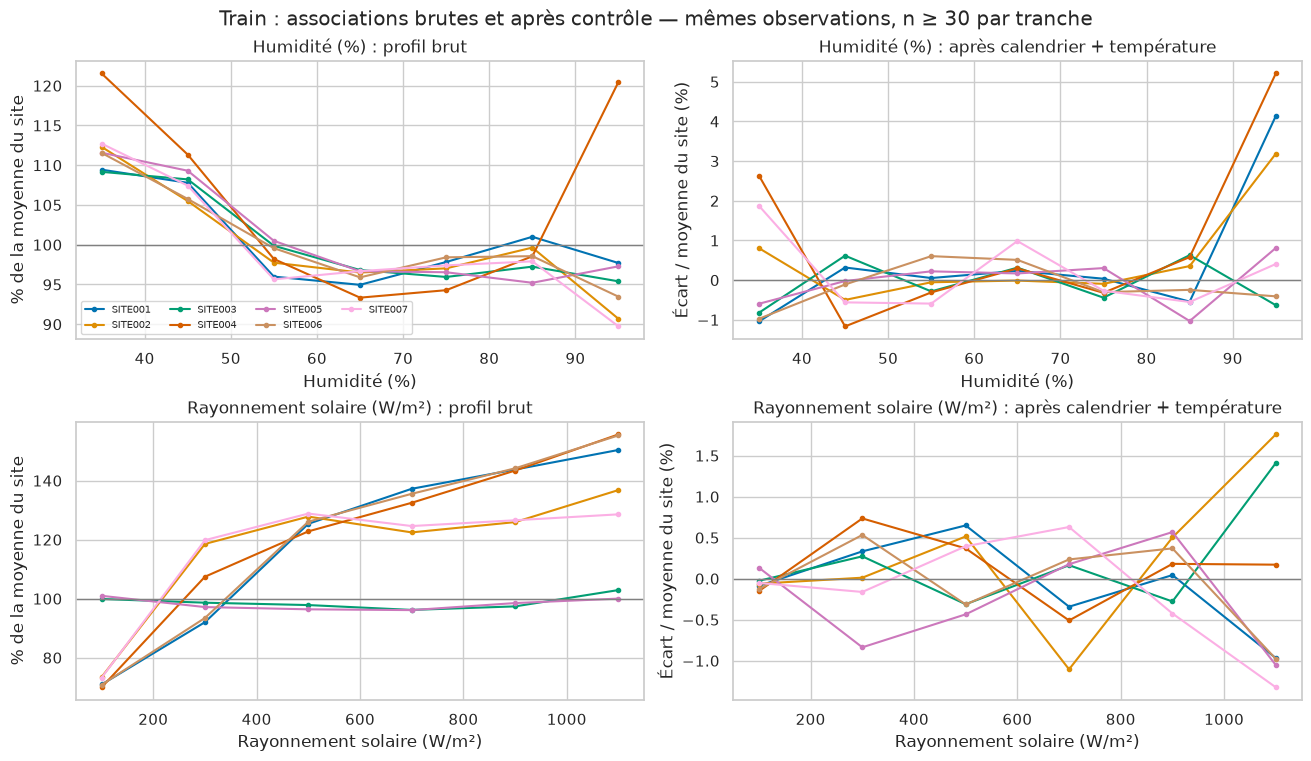

**Zoom sur les tranches hautes** : humidité 90–100 %, rayonnement 1 000–1 200 W/m². Effectifs de l’échantillon contrôlé ; écarts rapportés à la moyenne du site, après calendrier + température. Un écart absent indique moins de 30 observations. Ces moyennes n’ont pas de test de significativité.

,n_humidite_90_100,ecart_humidite_90_100_pct,n_solaire_1000_1200,ecart_solaire_1000_1200_pct
site,,,,
SITE001,43,4.14,269,-0.97
SITE002,37,3.19,235,1.76
SITE003,52,-0.63,250,1.41
SITE004,36,5.21,230,0.17
SITE005,43,0.81,255,-1.05
SITE006,43,-0.41,248,-0.98
SITE007,33,0.41,235,-1.32


**Constat sur les observations retenues :** maximum des corrélations absolues après calendrier + température : **Humidité (%) : 0.010** ; **Rayonnement solaire (W/m²) : 0.015**. Les profils et les deux sous-périodes permettent de voir ce qui persiste au-delà du calendrier. **Ces coefficients mesurent une association linéaire résiduelle, pas une importance de modèle.** Des écarts restent visibles dans certaines tranches, notamment à forte humidité : une corrélation linéaire faible ne résume donc pas toutes les relations. L’échantillon filtré, les effectifs des tranches, le contrôle discret et les possibles interactions limitent la conclusion. La présélection reste provisoire ; aucune colonne de fichier n’est supprimée.

In [2]:
EXTRA_WEATHER = {"humidity_percent": "Humidité (%)", "solar_irradiance_wm2": "Rayonnement solaire (W/m²)"}
extra_train = df.copy()
assert extra_train.timestamp.ge(TRAIN_START).all() and extra_train.timestamp.lt(TRAIN_END).all()
extra_train["temperature_bin"] = np.floor(extra_train.temperature_celsius / 5)
EXTRA_CALENDAR = ["site_id", "hour", "day_of_week", "month"]

def centered_weather(frame, variable):
    keys = [*EXTRA_CALENDAR, "temperature_bin"]
    sample = frame.dropna(subset=[TARGET, variable, *keys]).copy()
    group_n = sample.groupby(keys, observed=True)[variable].transform("size")
    sample = sample.loc[group_n.ge(3)].copy()
    for name, controls in [("calendar", EXTRA_CALENDAR), ("full", keys)]:
        means = sample.groupby(controls, observed=True)[[TARGET, variable]].transform("mean")
        sample[f"y_{name}"] = sample[TARGET] - means[TARGET]
        sample[f"x_{name}"] = sample[variable] - means[variable]
    return sample

def observed_correlation(x, y):
    return float(x.corr(y)) if len(x) > 1 and x.std() > 1e-12 and y.std() > 1e-12 else np.nan

extra_samples, extra_records = {}, []
for variable in EXTRA_WEATHER:
    sample = centered_weather(extra_train, variable)
    extra_samples[variable] = sample
    halves = {
        year: centered_weather(extra_train.loc[
            extra_train.timestamp.dt.year.eq(year) & extra_train.timestamp.dt.month.le(6)], variable)
        for year in [2023, 2024]
    }
    for site in SITES:
        group = sample.loc[sample.site_id.eq(site)]
        available = extra_train.loc[extra_train.site_id.eq(site), variable].notna().sum()
        record = {
            "variable": EXTRA_WEATHER[variable], "site": site, "n_commun": len(group),
            "couverture_pct": 100 * len(group) / available if available else np.nan,
            "r_brut": observed_correlation(group[variable], group[TARGET]),
            "r_calendrier": observed_correlation(group.x_calendar, group.y_calendar),
            "r_calendrier_temperature": observed_correlation(group.x_full, group.y_full),
        }
        for year, half in halves.items():
            values = half.loc[half.site_id.eq(site)]
            r = observed_correlation(values.x_full, values.y_full)
            record[f"H1_{year}"] = f"{r:+.3f} (n={len(values):,})" if pd.notna(r) else f"Non estimable (n={len(values):,})"
        extra_records.append(record)
extra_correlations = pd.DataFrame(extra_records)
display(Markdown(
    "**Corrélations sur échantillon commun** : couverture = part des paires météo/consommation connues retenues. "
    "Les colonnes H1 affichent la corrélation après calendrier + température et leur propre effectif."
))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(extra_correlations.set_index(["variable", "site"]))

extra_tail_records = []
extra_figure, axes = plt.subplots(2, 2, figsize=(13, 7.5), layout="constrained")
for row, (variable, label) in enumerate(EXTRA_WEATHER.items()):
    sample = extra_samples[variable].copy()
    edges = np.arange(30, 101, 10) if variable == "humidity_percent" else np.arange(0, 1201, 200)
    sample["tranche"] = pd.cut(sample[variable], edges, right=False)
    assert sample.tranche.notna().all(), "Adapter les bornes si de nouvelles valeurs sont présentes."
    profiles = sample.groupby(["site_id", "tranche"], observed=False).agg(
        n=(TARGET, "count"), mean=(TARGET, "mean"), adjusted=("y_full", "mean"))
    for site in SITES:
        group = profiles.loc[site]
        enough = group.n.ge(30)
        x = [v.mid for v in group.index]
        reference = extra_train.loc[extra_train.site_id.eq(site), TARGET].mean()
        tail = group.iloc[-1]
        extra_tail_records.append({
            "site": site, "variable": variable, "n": int(tail.n),
            "ecart_pct": float(100 * tail.adjusted / reference) if tail.n >= 30 else np.nan,
        })
        axes[row, 0].plot(x, (100 * group["mean"] / reference).where(enough), marker="o", markersize=3, label=site)
        axes[row, 1].plot(x, (100 * group.adjusted / reference).where(enough), marker="o", markersize=3, label=site)
    axes[row, 0].axhline(100, color="grey", linewidth=1)
    axes[row, 1].axhline(0, color="grey", linewidth=1)
    axes[row, 0].set(title=f"{label} : profil brut", ylabel="% de la moyenne du site", xlabel=label)
    axes[row, 1].set(title=f"{label} : après calendrier + température",
                     ylabel="Écart / moyenne du site (%)", xlabel=label)
axes[0, 0].legend(ncol=4, fontsize=7)
extra_figure.suptitle("Train : associations brutes et après contrôle — mêmes observations, n ≥ 30 par tranche")
plt.show()
plt.close(extra_figure)
extra_tail = pd.DataFrame(extra_tail_records)
extra_tail_table = pd.DataFrame(index=pd.Index(SITES, name="site"))
for variable, label in [("humidity_percent", "humidite_90_100"), ("solar_irradiance_wm2", "solaire_1000_1200")]:
    values = extra_tail.loc[extra_tail.variable.eq(variable)].set_index("site")
    extra_tail_table[f"n_{label}"] = values.n
    extra_tail_table[f"ecart_{label}_pct"] = values.ecart_pct
display(Markdown(
    "**Zoom sur les tranches hautes** : humidité 90–100 %, rayonnement 1 000–1 200 W/m². "
    "Effectifs de l’échantillon contrôlé ; écarts rapportés à la moyenne du site, après calendrier + température. "
    "Un écart absent indique moins de 30 observations. Ces moyennes n’ont pas de test de significativité."
))
display(extra_tail_table)

extra_max_correlations = extra_correlations.groupby("variable").r_calendrier_temperature.apply(lambda values: values.abs().max())
display(Markdown(
    "**Constat sur les observations retenues :** maximum des corrélations absolues après calendrier + température : "
    + " ; ".join(f"**{label} : {value:.3f}**" for label, value in extra_max_correlations.items())
    + ". Les profils et les deux sous-périodes permettent de voir ce qui persiste au-delà du calendrier. "
    "**Ces coefficients mesurent une association linéaire résiduelle, pas une importance de modèle.** "
    "Des écarts restent visibles dans certaines tranches, notamment à forte humidité : "
    "une corrélation linéaire faible ne résume donc pas toutes les relations. "
    "L’échantillon filtré, les effectifs des tranches, le contrôle discret et les possibles interactions limitent la conclusion. "
    "La présélection reste provisoire ; aucune colonne de fichier n’est supprimée."
))


## 8. is_working_hours : recalcul à partir des métadonnées

Le flag utilisé dans **df** est recalculé pour chaque site à partir de **profile.working_hours** et **profile.working_days** : jour autorisé **ET** heure de début incluse / heure de fin exclue. **0 = lundi, 6 = dimanche** ; **[0, 24]** couvre la journée entière. Les sept JSON sont lus dans **.data/ml/raw/metadata/**, sans utiliser leurs statistiques globales ni leurs annotations d'anomalies.

Le tableau compare le flag source, conservé dans **raw**, au flag recalculé sur les mêmes lignes à cible connue de **train**. **SITE003 (data center) et SITE005 (hôpital) ont un planning confirmé 24 h/24, 7 j/7 : leur flag vaut toujours 1.** La moyenne pour le flag 0 est affichée **Sans objet** lorsqu'aucune heure ne porte cet état ; cela ne signifie pas que le planning est inconnu. Les zéros de consommation sont conservés.

La carte présente la part des heures disponibles marquées travaillées par site et jour de semaine. Un planning hebdomadaire ne représente pas automatiquement les jours fériés, fermetures exceptionnelles ou une présence réelle. Ce flag est une **feature candidate**, dont le gain devra être comparé ensuite sur validation. Aucun fichier de données n'est modifié.

,horaires,jours_travailles
site,,
SITE001,08h–19h,"Lun, Mar, Mer, Jeu, Ven"
SITE002,06h–22h,"Lun, Mar, Mer, Jeu, Ven"
SITE003,24 h/24,7 j/7
SITE004,09h–21h,7 j/7
SITE005,24 h/24,7 j/7
SITE006,08h–19h,"Lun, Mar, Mer, Jeu, Ven"
SITE007,06h–22h,"Lun, Mar, Mer, Jeu, Ven"


**Train à cible connue : 8,318 flags recalculés différents de la source sur 89,780 lignes.** Avant recalcul : 0 flags manquants et 0 valeurs hors 0/1. Après recalcul : aucun flag manquant ou hors 0/1.

,n_differents_source,n_flag0,moyenne_flag0_kwh,n_flag1,moyenne_flag1_kwh
site,,,,,
SITE001,1699,8643,80.92,4184,171.86
SITE002,2449,6720,367.36,6102,868.59
SITE003,0,0,Sans objet,12813,845.61
SITE004,0,6418,160.63,6419,362.89
SITE005,0,0,Sans objet,12830,539.42
SITE006,1704,8667,79.61,4177,170.73
SITE007,2466,6737,369.51,6070,883.87


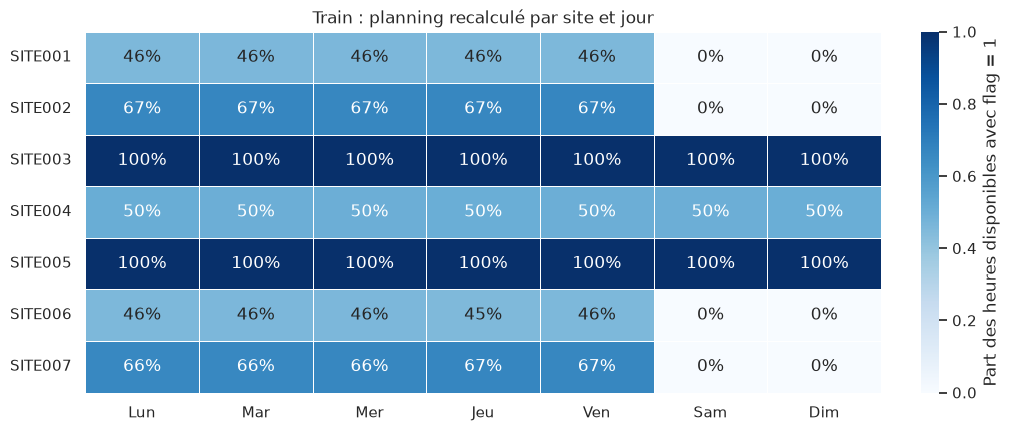

**Interprétation :** le flag combine les horaires et les jours déclarés pour chaque site. Les moyennes de consommation par état sont descriptives ; elles ne prouvent pas un apport indépendant du site et du calendrier. **is_working_hours est retenu dans la liste des futures features**, avec un intérêt prédictif à comparer avec/sans ce flag. Le CSV et les Parquet existants restent intacts.

In [2]:
ACTIVITY = "is_working_hours"
assert df.timestamp.ge(TRAIN_START).all() and df.timestamp.lt(TRAIN_END).all()
assert df[ACTIVITY].notna().all() and df[ACTIVITY].isin([0, 1]).all()
activity_source = raw.loc[df.index, ACTIVITY]
activity_changed = activity_source.ne(df[ACTIVITY]).fillna(True)
activity_missing = int(activity_source.isna().sum())
activity_invalid = int((activity_source.notna() & ~activity_source.isin([0, 1])).sum())
day_labels = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
activity_schedules = pd.DataFrame.from_dict({
    site: {
        "horaires": "24 h/24" if planning["working_hours"] == [0, 24] else f"{planning['working_hours'][0]:02d}h–{planning['working_hours'][1]:02d}h",
        "jours_travailles": "7 j/7" if planning["working_days"] == list(range(7)) else ", ".join(day_labels[day] for day in planning["working_days"]),
    }
    for site, planning in SITE_SCHEDULES.items()
}, orient="index").reindex(SITES)
activity_schedules.index.name = "site"
display(activity_schedules)
display(Markdown(
    f"**Train à cible connue : {int(activity_changed.sum()):,} flags recalculés différents de la source "
    f"sur {len(df):,} lignes.** Avant recalcul : {activity_missing} flags manquants et "
    f"{activity_invalid} valeurs hors 0/1. Après recalcul : aucun flag manquant ou hors 0/1."
))

activity_counts = df.groupby(["site_id", ACTIVITY], observed=True)[TARGET].size().unstack().reindex(
    index=SITES, columns=[0, 1]
).fillna(0).astype(int)
activity_means = df.groupby(["site_id", ACTIVITY], observed=True)[TARGET].mean().unstack().reindex(
    index=SITES, columns=[0, 1]
)
activity_table = pd.DataFrame({
    "n_differents_source": activity_changed.groupby(df.site_id).sum().reindex(SITES).astype(int),
    "n_flag0": activity_counts[0], "moyenne_flag0_kwh": activity_means[0],
    "n_flag1": activity_counts[1], "moyenne_flag1_kwh": activity_means[1],
})
activity_table.index.name = "site"
display(activity_table.style.format(
    {"moyenne_flag0_kwh": "{:.2f}", "moyenne_flag1_kwh": "{:.2f}"}, na_rep="Sans objet",
))

activity_grid = df.groupby(
    ["site_id", df.timestamp.dt.dayofweek.rename("jour")], observed=True
)[ACTIVITY].mean().unstack("jour").reindex(index=SITES, columns=range(7))
activity_figure, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
sns.heatmap(
    activity_grid, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1,
    xticklabels=day_labels, linewidths=.4,
    cbar_kws={"label": "Part des heures disponibles avec flag = 1"}, ax=ax,
)
ax.set(title="Train : planning recalculé par site et jour", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.show()
plt.close(activity_figure)
display(Markdown(
    "**Interprétation :** le flag combine les horaires et les jours déclarés pour chaque site. "
    "Les moyennes de consommation par état sont descriptives ; elles ne prouvent pas un apport "
    "indépendant du site et du calendrier. **is_working_hours est retenu dans la liste des futures features**, "
    "avec un intérêt prédictif à comparer avec/sans ce flag. Le CSV et les Parquet existants restent intacts."
))


## 9. Choix des colonnes et nettoyage prévu

Les entrées de la **présélection provisoire du premier jeu réduit** sont le site, le calendrier, les lags 24 h et 7 jours, la température comme candidate météorologique, et **is_working_hours recalculé à partir des métadonnées**. L’exploration justifie des candidats ; leur apport prédictif sera évalué ensuite.

Les règles restent simples : clés site/heure uniques, calendrier cohérent, lags calculés à la date exacte sur l’historique avant d’exclure les cibles NULL, zéros et pics conservés. Les NULL des features restent présents : leur traitement dépendra du modèle et sera appris uniquement sur train. Le flag is_working_hours est recalculé en mémoire avec le planning propre à chaque site, en conservant le CSV original. Aucune imputation, standardisation ou suppression automatique de pics ici.

Les champs suivants ne font pas partie de ce premier jeu réduit :

| Champs écartés | Raison |
| --- | --- |
| consumption_euros | Coût contemporain lié à la cible et inconnu pour l’heure à prévoir. |
| site_name, site_type | Informations redondantes avec le site pour les sept sites connus. |
| day_name, is_weekend | Informations déjà représentées par day_of_week. |
| humidity_percent, solar_irradiance_wm2 | Associations après contrôle et stabilité étudiées en section 7 ; cette exploration ne démontre pas leur inutilité pour toutes les interactions ou périodes. |

La liste finale est affichée à la fin du notebook. Le schéma est défini dans training.data et utilisé par le script de préparation et les entraînements. Le notebook ne modifie aucun Parquet.


In [ ]:
assert len(FEATURES) == 8 and len(PARQUET_COLUMNS) == len(set(PARQUET_COLUMNS)) == 10
display(Markdown(
    "**Schéma retenu : 8 entrées + 1 cible + 1 repère chronologique = 10 colonnes.** "
    "Le timestamp sert à l’ordre chronologique et aux vérifications ; la consommation est la cible. "
    "Le schéma est partagé avec les scripts Python ; cette cellule ne modifie aucun fichier."
))


## 10. Génération des Parquet avec Python et Docker

La préparation est exécutée par **training.prepare_data**, séparément du notebook. Elle utilise le CSV et les métadonnées en lecture seule et écrit uniquement les trois Parquet. Elle ne lance aucun entraînement et ne contacte pas MLflow.

Depuis la racine du projet, avec Docker et la configuration **.env** habituelle en place, sous Linux ou WSL :

~~~bash
mkdir -p .data/ml/splits
docker compose --profile preparation \
  -f compose.yaml \
  -f services/ml-service/compose.training.yaml \
  run --build --rm --no-deps --user "$(id -u):$(id -g)" ml-prepare
~~~

Le dossier de sortie est créé par l’utilisateur avant le lancement. Le conteneur utilise son UID/GID pour écrire des fichiers accessibles sur le poste. Le lancement remplace les Parquet existants uniquement après validation des trois jeux et vérification de leur lecture.

Le script recalcule **is_working_hours** depuis les mêmes métadonnées, calcule les lags aux dates exactes avant d’exclure les cibles NULL, conserve les dix colonnes du schéma et applique les bornes suivantes :

| Jeu | Période |
| --- | --- |
| train | Du 1er janvier 2023 au 30 juin 2024 inclus |
| validation | Du 1er juillet au 30 septembre 2024 inclus |
| test | Du 1er octobre au 31 décembre 2024 inclus |

Les zéros, les pics et les NULL des features sont conservés. Les analyses et le choix des colonnes restent fondés sur train ; le jeu test est préparé puis réservé à l’évaluation finale. Les entraînements lisent uniquement train et validation.


## Liste des colonnes retenues dans les Parquet

**Présélection provisoire de huit features pour les prochains essais :**

| Feature | Rôle |
| --- | --- |
| site_id | Distinguer les profils des sites. |
| hour | Représenter le rythme dans la journée. |
| day_of_week | Représenter le rythme hebdomadaire. |
| month | Représenter les variations saisonnières. |
| is_working_hours | Planning du site recalculé avec working_hours ET working_days des métadonnées ; gain à comparer ensuite. |
| lag_24h | Consommation du même site à la même heure la veille. |
| lag_168h | Consommation du même site à la même heure sept jours auparavant. |
| temperature_celsius | Candidate météo issue de l’analyse exploratoire ; disponibilité à l’heure de prévision à confirmer. |

**Cible : consumption_kwh.**  
**Contexte : timestamp**, pour conserver l’ordre et les découpages temporels ; il n’est pas une entrée directe du modèle.

**Total : dix colonnes, dans cet ordre :** timestamp, site_id, hour, day_of_week, month, is_working_hours, lag_24h, lag_168h, temperature_celsius, consumption_kwh.

Le script Python exclut les cibles NULL après calcul des lags et conserve les zéros et les NULL des features. **La génération se lance uniquement avec la commande de préparation ; exécuter ce notebook ne crée ni ne remplace les Parquet.**

Les analyses de l’humidité et du rayonnement figurent en section 7 ; le recalcul de is_working_hours et la comparaison au flag source figurent en section 8. L’intérêt prédictif des features sera comparé ensuite sur train et validation. Les prochaines générations Python utilisent ce schéma.
